In [ ]:
import pathlib

In [ ]:
import marimo as mo
import matplotlib.colors as mcolors
import matplotlib.legend_handler as mlegend_handler
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import pandas as pd
import requests
import seaborn as sns
from teeplot import teeplot as tp
from watermark import watermark

In [ ]:
mo.md(
    f"""
```Text
{watermark(
    current_date=True,
    iso8601=True,
    machine=True,
    updated=True,
    python=True,
    iversions=True,
    globals_=globals(),
)}
```
"""
)

```Text
Last updated: 2026-10-20T02:30:22.470147+00:00

Python implementation: CPython
Python version       : 3.10.12
IPython version      : 7.31.1

Compiler    : GCC 11.4.0
OS          : Linux
Release     : 6.8.0-1064-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 4
Architecture: 64bit

requests  : 2.34.2
pandas    : 2.2.3
matplotlib: 3.10.7
marimo    : 0.23.2
teeplot   : 1.4.2
seaborn   : 0.13.2

```

## Data

Prototype redraws of a batch of figures from Simon, Koopman,
Eisenberg, Zaman, Moreno & Polanco, "An allele-based model of
coronavirus evolution under population immunity" (medRxiv,
<https://doi.org/10.1101/2025.09.15.25335781>, v3), reusing the
strain-dynamics rendering style already established for Figure 3
in `2026-09-26-figrender.py`.

Each underlying trajectory is hosted on OSF as a `FigN.csv` (or,
for `Fig11b`, tab-delimited `.txt`) file with the same column
convention as `Fig3.csv`: `TIME` plus a `J**` prevalence column
and (where present) a `SuscToI**` susceptibility column per
2-allele strain (`02`, `03`, `12`, `13`). Datasets for Figures
11 and 12 omit the susceptibility columns and are rendered as a
single prevalence panel; the rest render as a two-panel
susceptibility+prevalence figure matching Figure 3's layout.

Figure numbers below refer to the v3 manuscript. Figures 11 and
12 are each a single multi-panel manuscript figure (11: left/
center/right for joint-immunity `mij` = 0, 0.2, 0.4; 12: left/
right for Case 1 allele-based vs. Case 2 strain-based immunity),
split here into separate `11a`/`11b`/`11c` and `12a`/`12b` cells
to match how the underlying data is hosted on OSF.

In [ ]:
def fetch_osf(slug, sep=","):
    cache_path = pathlib.Path("/tmp") / slug
    url = f"https://osf.io/{slug}/download"
    if not cache_path.exists():
        print(f"downloading {url} -> {cache_path}")
        resp = requests.get(url, allow_redirects=True, timeout=120)
        resp.raise_for_status()
        cache_path.write_bytes(resp.content)
    else:
        print(f"reusing cached {cache_path}")
    print(f"size: {cache_path.stat().st_size} bytes")
    df = pd.read_csv(cache_path, sep=sep)
    df.columns = [col.replace(":1", "") for col in df.columns]
    return df

In [ ]:
def prep_long(df):
    long_df = df.melt(
        id_vars="TIME",
        var_name="variable",
        value_name="value",
    )
    long_df["strain"] = long_df["variable"].str.slice(-2)
    is_susceptibility = long_df["variable"].str.startswith("Susc")
    long_df["quantity"] = is_susceptibility.map(
        {True: "susceptibility", False: "prevalence"},
    )
    zeroed_prevalence = (long_df["quantity"] == "prevalence") & (
        long_df["value"] == 0
    )
    long_df.loc[zeroed_prevalence, "value"] = float("nan")
    has_susceptibility = is_susceptibility.any()
    return long_df, has_susceptibility

## Renders

One cell per figure: fetch its OSF dataset, then render with the
shared `plot_manuscript_figure` helper below. The x-axis maximum
for each is set to match the corresponding original figure.

In [ ]:
STRAIN_ORDER = ["02", "03", "12", "13"]
# Same named-color palette as 2026-09-26-figrender.py, so strain
# identity reads consistently across notebooks.
PALETTE = {
    "02": "#373061",
    "03": "#3cb371",
    "12": "#1e90ff",
    "13": "#ff8671",
}
DASHES = {
    "02": "",
    "03": "",
    "12": (0.8, 2.6),
    "13": (4, 1.5),
}
DOTTED_RGB = mcolors.to_rgb(PALETTE["12"])

def plot_manuscript_figure(
    long_df,
    has_susceptibility,
    name,
    xmax,
    pathlib_stem,
    show_susceptibility=True,
    prevalence_scale=1,
):
    prevalence_df = long_df[long_df["quantity"] == "prevalence"]
    has_susceptibility = has_susceptibility and show_susceptibility
    nrows = 2 if has_susceptibility else 1
    # Panel heights match the original layouts at prevalence_scale=1;
    # prevalence_scale stretches only the prevalence panel.
    if has_susceptibility:
        height_ratios = [1, prevalence_scale]
        figheight = 3.9 / 2 * (1 + prevalence_scale)
    else:
        height_ratios = [1]
        figheight = 2.2 * prevalence_scale
    figsize = (4.6, figheight)

    outattrs = {"a": f"{name.lower()}-strain-dynamics"}
    if not show_susceptibility:
        outattrs["susceptibility"] = False
    if prevalence_scale != 1:
        outattrs["prevalence-scale"] = prevalence_scale

    with tp.teed(
        plt.subplots,
        nrows=nrows,
        ncols=1,
        squeeze=False,
        figsize=figsize,
        gridspec_kw={"height_ratios": height_ratios},
        teeplot_outattrs=outattrs,
        teeplot_show=True,
        teeplot_subdir=pathlib_stem,
    ) as (fig, axes_grid):
        axes = axes_grid[:, 0]
        if has_susceptibility:
            susceptibility_df = long_df[
                long_df["quantity"] == "susceptibility"
            ]
            ax_susc, ax_prev = axes
            sns.lineplot(
                data=susceptibility_df,
                x="TIME",
                y="value",
                hue="strain",
                hue_order=STRAIN_ORDER,
                style="strain",
                style_order=STRAIN_ORDER,
                dashes=DASHES,
                palette=PALETTE,
                linewidth=1.2,
                legend=True,
                ax=ax_susc,
            )
            ax_susc.set_ylabel("Host\nSusceptibility")
            ax_susc.set_xlabel("")
            ax_susc.set_xticklabels([])
            ax_susc.set_yticks([0.0, 0.5, 1.0])
            ax_susc.set_ylim(bottom=0.0)
            legend_ax = ax_susc
        else:
            (ax_prev,) = axes
            legend_ax = None

        sns.lineplot(
            data=prevalence_df,
            x="TIME",
            y="value",
            hue="strain",
            hue_order=STRAIN_ORDER,
            style="strain",
            style_order=STRAIN_ORDER,
            dashes=DASHES,
            palette=PALETTE,
            linewidth=1.2,
            legend=(legend_ax is None),
            ax=ax_prev,
        )
        ax_prev.set_ylabel("Strain\nPrevalence")
        ax_prev.set_xlabel("Time")
        if legend_ax is None:
            legend_ax = ax_prev

        # Widen 12's dotted line beyond the shared base linewidth
        # so its sparser dots stay legible, and add a thin solid
        # underlay so the trajectory still reads as continuous
        # between dots.
        for ax in axes:
            for line in list(ax.lines):
                if mcolors.to_rgb(line.get_color()) == DOTTED_RGB:
                    xdata, ydata = line.get_data()
                    ax.plot(
                        xdata,
                        ydata,
                        color=line.get_color(),
                        linewidth=0.6,
                        zorder=line.get_zorder() - 0.1,
                        solid_capstyle="round",
                    )
                    line.set_linewidth(2.8)
            ax.set_xlim(left=0, right=xmax)

        sns.despine(fig=fig)
        fig.tight_layout()

        # Fold the "strain" title into the legend's single row as
        # a label-only dummy entry, rather than a separate title
        # line.
        legend = legend_ax.get_legend()
        handles = legend.legend_handles
        labels = [t.get_text() for t in legend.get_texts()]
        legend.remove()
        for i, (handle, label) in enumerate(zip(handles, labels)):
            if label == "12":
                # Denser dashes than the plotted line so the
                # short legend key still reads clearly as dotted.
                handle.set_linewidth(2.8)
                handle.set_dashes([0.8, 1.2])
                # Pair with a thin solid proxy so the key matches
                # the plotted line's solid-underlay treatment.
                solid_proxy = mlines.Line2D(
                    [],
                    [],
                    color=handle.get_color(),
                    linewidth=0.6,
                    solid_capstyle="round",
                )
                handles[i] = (solid_proxy, handle)
        dummy = mlines.Line2D([], [], linestyle="none", label="Strain")
        fig.legend(
            handles=[dummy, *handles],
            labels=["Strain", *labels],
            loc="upper center",
            # Hold the legend a fixed physical distance above the
            # axes, regardless of figure height.
            bbox_to_anchor=(0.5, 1 + 0.23 / figheight),
            ncol=len(labels) + 1,
            frameon=False,
            handlelength=1.8,
            handletextpad=0.6,
            columnspacing=1.2,
            handler_map={tuple: mlegend_handler.HandlerTuple(ndivide=1)},
        )
    return fig

downloading https://osf.io/sz4f9/download -> /tmp/sz4f9
size: 195416 bytes
teeplots/2026-09-29-manuscript-figures/a=fig2-strain-dynamics+viz=subplots+ext=.pdf
teeplots/2026-09-29-manuscript-figures/a=fig2-strain-dynamics+viz=subplots+ext=.png


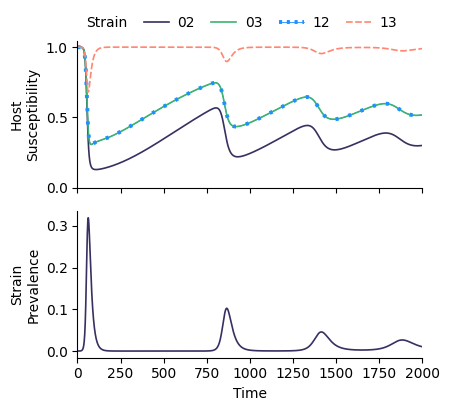

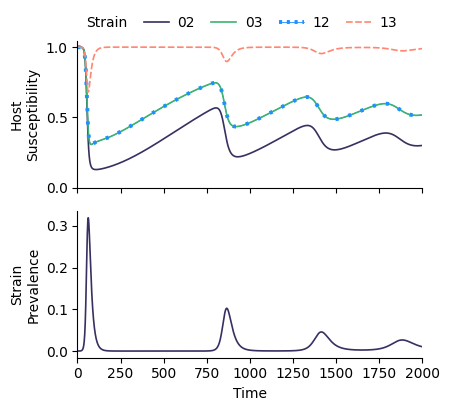

In [ ]:
_df = fetch_osf("sz4f9")
_long_df, _has_susceptibility = prep_long(_df)
plot_manuscript_figure(
    _long_df,
    _has_susceptibility,
    "Fig2",
    2000,
    pathlib.Path(__file__).stem,
)

downloading https://osf.io/sd6ja/download -> /tmp/sd6ja
size: 270941 bytes
teeplots/2026-09-29-manuscript-figures/a=fig4-strain-dynamics+viz=subplots+ext=.pdf
teeplots/2026-09-29-manuscript-figures/a=fig4-strain-dynamics+viz=subplots+ext=.png


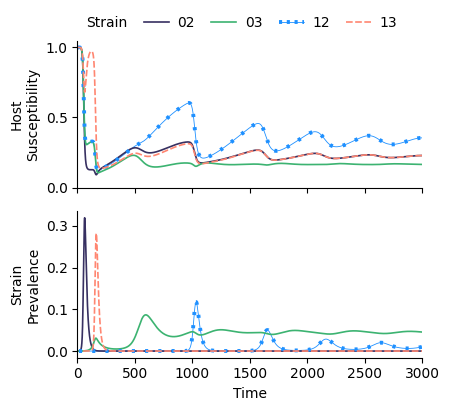

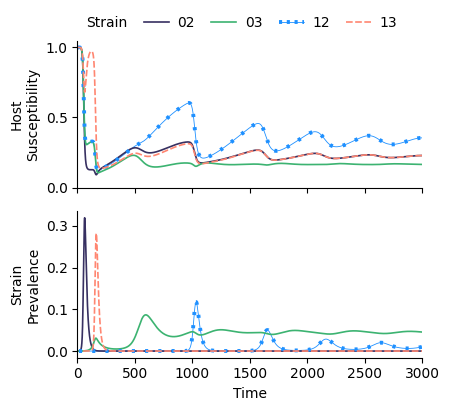

In [ ]:
_df = fetch_osf("sd6ja")
_long_df, _has_susceptibility = prep_long(_df)
plot_manuscript_figure(
    _long_df,
    _has_susceptibility,
    "Fig4",
    3000,
    pathlib.Path(__file__).stem,
)

downloading https://osf.io/wx3du/download -> /tmp/wx3du
size: 274710 bytes
teeplots/2026-09-29-manuscript-figures/a=fig5-strain-dynamics+prevalence-scale=2+susceptibility=False+viz=subplots+ext=.pdf
teeplots/2026-09-29-manuscript-figures/a=fig5-strain-dynamics+prevalence-scale=2+susceptibility=False+viz=subplots+ext=.png


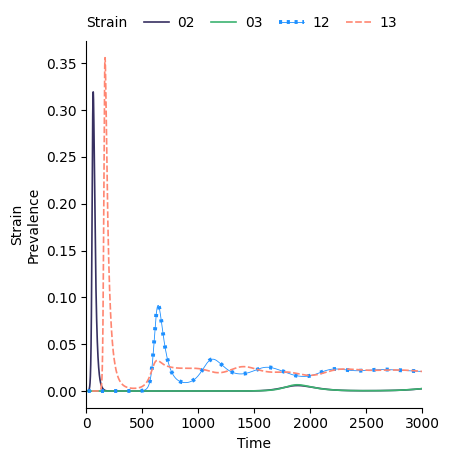

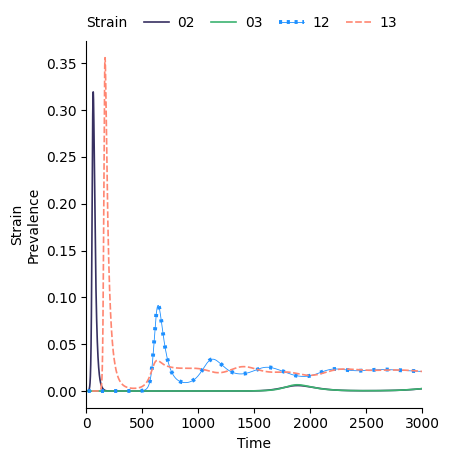

In [ ]:
_df = fetch_osf("wx3du")
_long_df, _has_susceptibility = prep_long(_df)
plot_manuscript_figure(
    _long_df,
    _has_susceptibility,
    "Fig5",
    3000,
    pathlib.Path(__file__).stem,
    show_susceptibility=False,
    prevalence_scale=2,
)

downloading https://osf.io/xjdnq/download -> /tmp/xjdnq
size: 274893 bytes
teeplots/2026-09-29-manuscript-figures/a=fig6-strain-dynamics+prevalence-scale=2+viz=subplots+ext=.pdf
teeplots/2026-09-29-manuscript-figures/a=fig6-strain-dynamics+prevalence-scale=2+viz=subplots+ext=.png


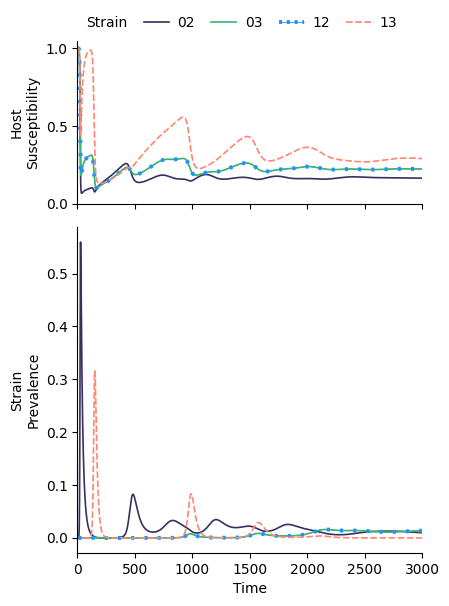

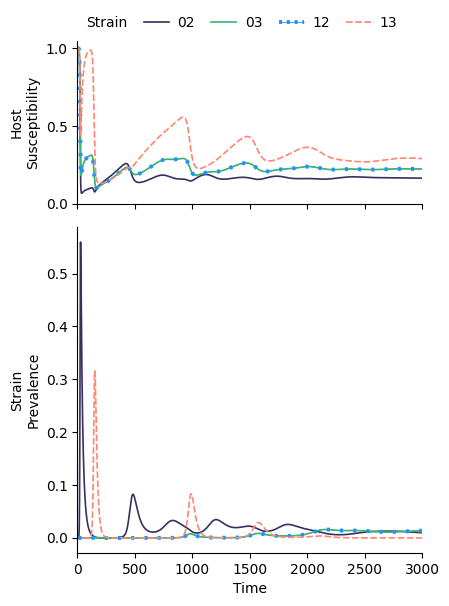

In [ ]:
_df = fetch_osf("xjdnq")
_long_df, _has_susceptibility = prep_long(_df)
plot_manuscript_figure(
    _long_df,
    _has_susceptibility,
    "Fig6",
    3000,
    pathlib.Path(__file__).stem,
    prevalence_scale=2,
)

downloading https://osf.io/vmw46/download -> /tmp/vmw46
size: 271854 bytes
teeplots/2026-09-29-manuscript-figures/a=fig7-strain-dynamics+viz=subplots+ext=.pdf
teeplots/2026-09-29-manuscript-figures/a=fig7-strain-dynamics+viz=subplots+ext=.png


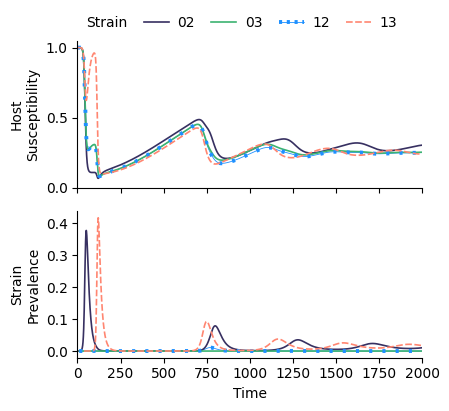

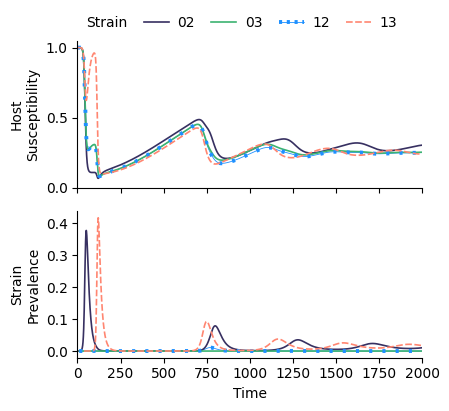

In [ ]:
_df = fetch_osf("vmw46")
_long_df, _has_susceptibility = prep_long(_df)
plot_manuscript_figure(
    _long_df,
    _has_susceptibility,
    "Fig7",
    2000,
    pathlib.Path(__file__).stem,
)

downloading https://osf.io/tzqxv/download -> /tmp/tzqxv
size: 271926 bytes
teeplots/2026-09-29-manuscript-figures/a=fig8-strain-dynamics+prevalence-scale=2+viz=subplots+ext=.pdf
teeplots/2026-09-29-manuscript-figures/a=fig8-strain-dynamics+prevalence-scale=2+viz=subplots+ext=.png


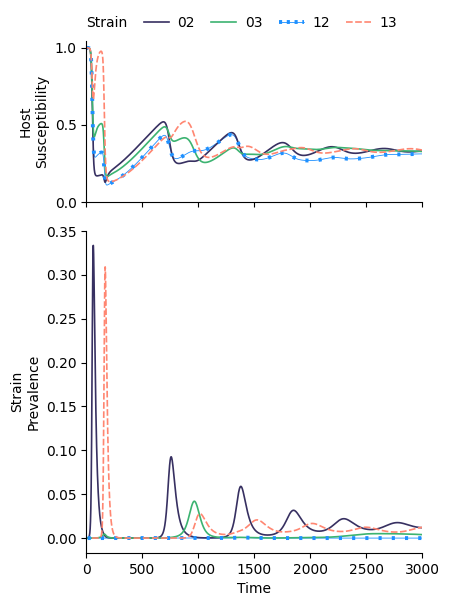

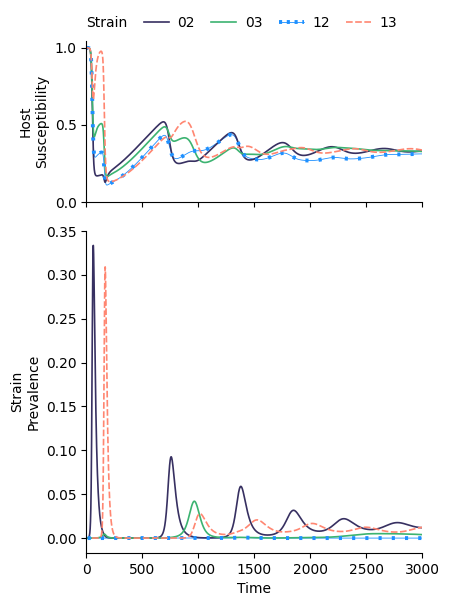

In [ ]:
_df = fetch_osf("tzqxv")
_long_df, _has_susceptibility = prep_long(_df)
plot_manuscript_figure(
    _long_df,
    _has_susceptibility,
    "Fig8",
    3000,
    pathlib.Path(__file__).stem,
    prevalence_scale=2,
)

downloading https://osf.io/vbt2y/download -> /tmp/vbt2y
size: 274725 bytes
teeplots/2026-09-29-manuscript-figures/a=fig9-strain-dynamics+viz=subplots+ext=.pdf
teeplots/2026-09-29-manuscript-figures/a=fig9-strain-dynamics+viz=subplots+ext=.png


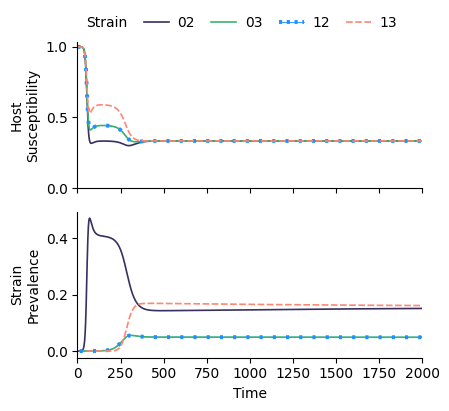

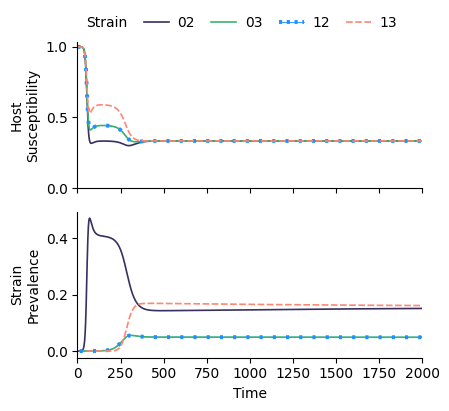

In [ ]:
_df = fetch_osf("vbt2y")
_long_df, _has_susceptibility = prep_long(_df)
plot_manuscript_figure(
    _long_df,
    _has_susceptibility,
    "Fig9",
    2000,
    pathlib.Path(__file__).stem,
)

downloading https://osf.io/e67fb/download -> /tmp/e67fb
size: 272624 bytes
teeplots/2026-09-29-manuscript-figures/a=fig10-strain-dynamics+viz=subplots+ext=.pdf
teeplots/2026-09-29-manuscript-figures/a=fig10-strain-dynamics+viz=subplots+ext=.png


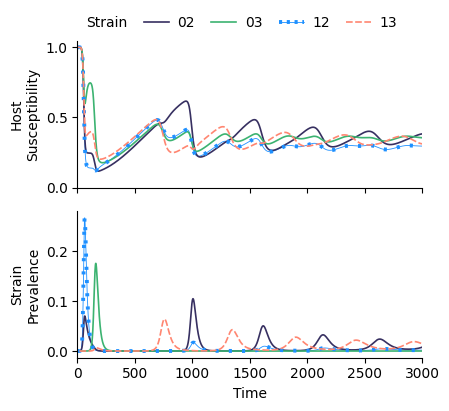

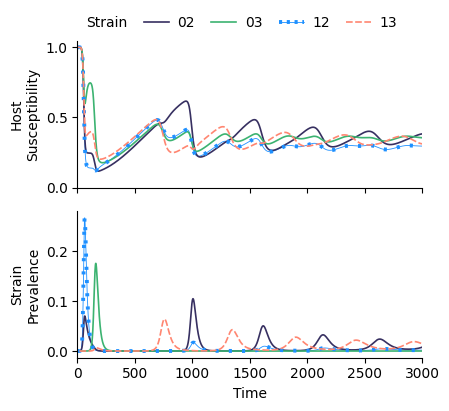

In [ ]:
_df = fetch_osf("e67fb")
_long_df, _has_susceptibility = prep_long(_df)
plot_manuscript_figure(
    _long_df,
    _has_susceptibility,
    "Fig10",
    3000,
    pathlib.Path(__file__).stem,
)

downloading https://osf.io/wkd37/download -> /tmp/wkd37
size: 143997 bytes
teeplots/2026-09-29-manuscript-figures/a=fig11a-strain-dynamics+viz=subplots+ext=.pdf
teeplots/2026-09-29-manuscript-figures/a=fig11a-strain-dynamics+viz=subplots+ext=.png


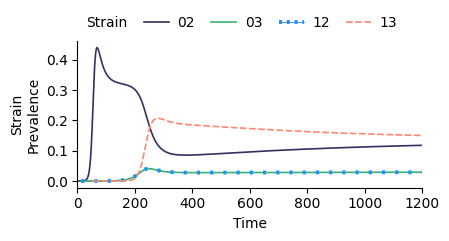

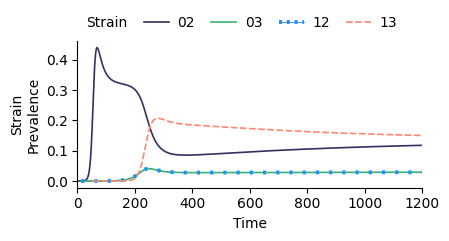

In [ ]:
_df = fetch_osf("wkd37")
_long_df, _has_susceptibility = prep_long(_df)
plot_manuscript_figure(
    _long_df,
    _has_susceptibility,
    "Fig11a",
    1200,
    pathlib.Path(__file__).stem,
)

downloading https://osf.io/shm8d/download -> /tmp/shm8d
size: 143952 bytes
teeplots/2026-09-29-manuscript-figures/a=fig11b-strain-dynamics+viz=subplots+ext=.pdf
teeplots/2026-09-29-manuscript-figures/a=fig11b-strain-dynamics+viz=subplots+ext=.png


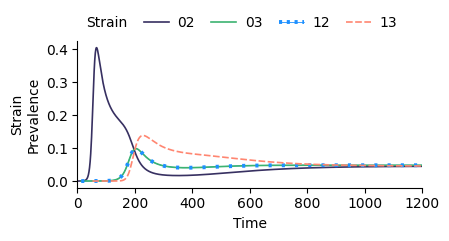

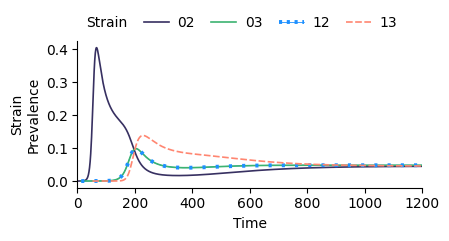

In [ ]:
_df = fetch_osf("shm8d", sep="\t")
_long_df, _has_susceptibility = prep_long(_df)
plot_manuscript_figure(
    _long_df,
    _has_susceptibility,
    "Fig11b",
    1200,
    pathlib.Path(__file__).stem,
)

downloading https://osf.io/3uxqd/download -> /tmp/3uxqd
size: 144027 bytes
teeplots/2026-09-29-manuscript-figures/a=fig11c-strain-dynamics+viz=subplots+ext=.pdf
teeplots/2026-09-29-manuscript-figures/a=fig11c-strain-dynamics+viz=subplots+ext=.png


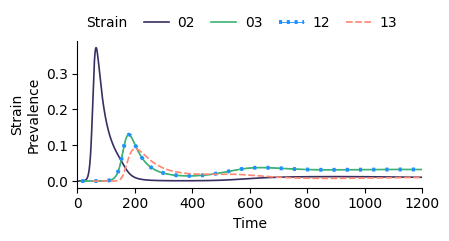

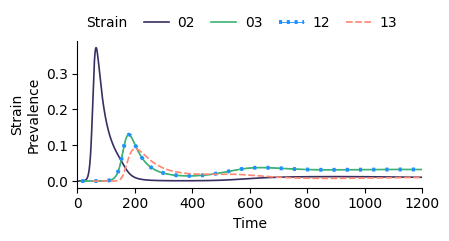

In [ ]:
_df = fetch_osf("3uxqd")
_long_df, _has_susceptibility = prep_long(_df)
plot_manuscript_figure(
    _long_df,
    _has_susceptibility,
    "Fig11c",
    1200,
    pathlib.Path(__file__).stem,
)

downloading https://osf.io/zy5aq/download -> /tmp/zy5aq
size: 144003 bytes
teeplots/2026-09-29-manuscript-figures/a=fig12a-strain-dynamics+viz=subplots+ext=.pdf
teeplots/2026-09-29-manuscript-figures/a=fig12a-strain-dynamics+viz=subplots+ext=.png


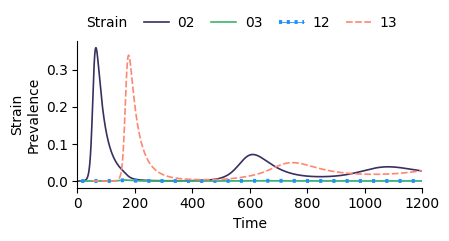

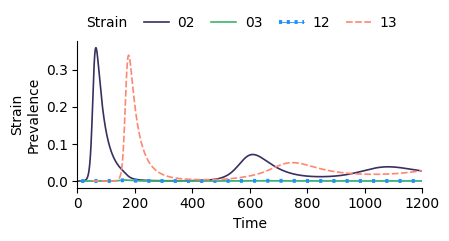

In [ ]:
_df = fetch_osf("zy5aq")
_long_df, _has_susceptibility = prep_long(_df)
plot_manuscript_figure(
    _long_df,
    _has_susceptibility,
    "Fig12a",
    1200,
    pathlib.Path(__file__).stem,
)

downloading https://osf.io/uk5sc/download -> /tmp/uk5sc
size: 143968 bytes
teeplots/2026-09-29-manuscript-figures/a=fig12b-strain-dynamics+viz=subplots+ext=.pdf
teeplots/2026-09-29-manuscript-figures/a=fig12b-strain-dynamics+viz=subplots+ext=.png


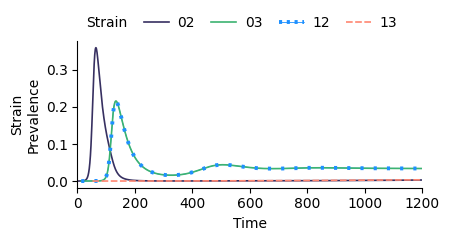

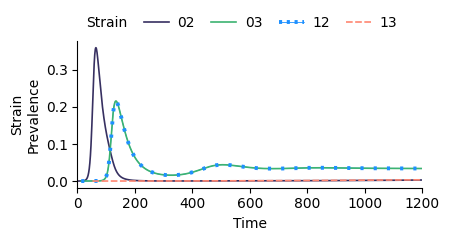

In [ ]:
_df = fetch_osf("uk5sc")
_long_df, _has_susceptibility = prep_long(_df)
plot_manuscript_figure(
    _long_df,
    _has_susceptibility,
    "Fig12b",
    1200,
    pathlib.Path(__file__).stem,
)

downloading https://osf.io/xsk4t/download -> /tmp/xsk4t
size: 143509 bytes
teeplots/2026-09-29-manuscript-figures/a=fig13-strain-dynamics+viz=subplots+ext=.pdf
teeplots/2026-09-29-manuscript-figures/a=fig13-strain-dynamics+viz=subplots+ext=.png


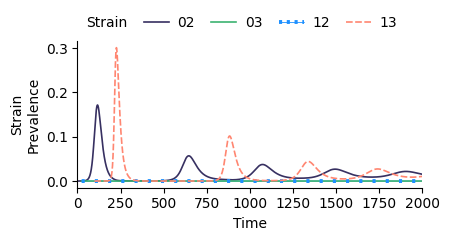

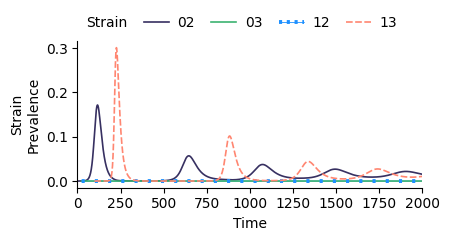

In [ ]:
_df = fetch_osf("xsk4t")
_long_df, _has_susceptibility = prep_long(_df)
plot_manuscript_figure(
    _long_df,
    _has_susceptibility,
    "Fig13",
    2000,
    pathlib.Path(__file__).stem,
)